In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = "images/image.jpg"

image = cv2.imread(image_path)

print("Shape:", image.shape)
print("Dtype:", image.dtype)

Shape: (2400, 1320, 3)
Dtype: uint8


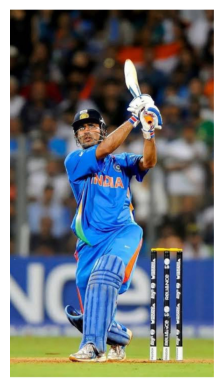

In [2]:
image_rgb = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis('off')
plt.show()

# Resize

In [3]:
# cv2.resize(image, (width, height))

resized = cv2.resize(image,(660,1200))

print('Original: ',image.shape)
print('Resized:  ',resized.shape)

Original:  (2400, 1320, 3)
Resized:   (1200, 660, 3)


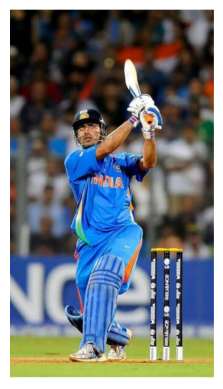

In [4]:
resized_rgb = cv2.cvtColor(resized,cv2.COLOR_BGR2RGB)

plt.imshow(resized_rgb)
plt.axis('off')
plt.show()

In [5]:
# Resize using scale
scale = 0.5

resized_half = cv2.resize(
    image,
    None,
    fx=scale,
    fy=scale
)

print(resized_half.shape)

(1200, 660, 3)


# Crop

In [17]:
cropped = image[300:900, 300:1000]

print("Original:", image.shape)
print("Cropped:", cropped.shape)

Original: (2400, 1320, 3)
Cropped: (600, 700, 3)


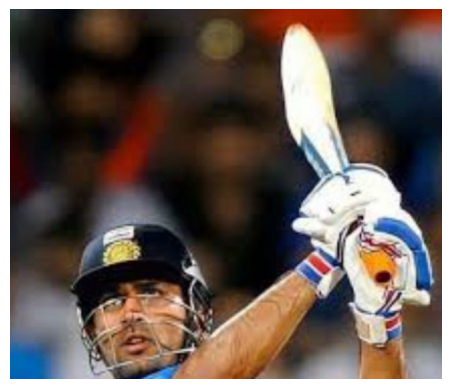

In [18]:
cropped_rgb = cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB)

plt.imshow(cropped_rgb)
plt.axis("off")
plt.show()

# Rotate

In [24]:
height, width = image.shape[:2]

centre = (width//2,height//2)

rotation_matrix = cv2.getRotationMatrix2D(
    centre,
    45,
    1.0
)

rotated = cv2.warpAffine(
    image,
    rotation_matrix,
    (width,height)
)

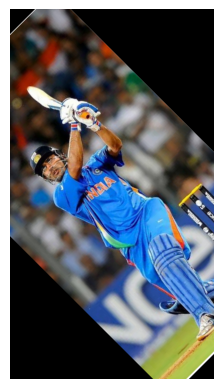

In [25]:
rotated_rgb = cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB)

plt.imshow(rotated_rgb)
plt.axis("off")
plt.show()

# Flip

In [26]:
flipped_horizontal = cv2.flip(image, 1)
flipped_vertical = cv2.flip(image, 0)
flipped_both = cv2.flip(image, -1)

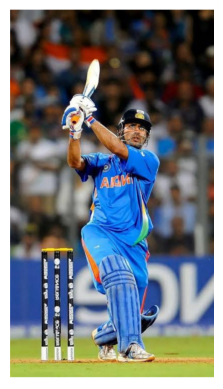

In [30]:
flipped_rgb = cv2.cvtColor(flipped_horizontal, cv2.COLOR_BGR2RGB)

plt.imshow(flipped_rgb)
plt.axis("off")
plt.show()

# Translate 
```
Translation means moving the image horizontally and/or vertically.

In [32]:
M = np.float32([
    [1, 0, 100],
    [0, 1, 50]
])

# x → +100 pixels
# y → +50 pixels

In [33]:
height, width = image.shape[:2]

translated = cv2.warpAffine(
    image,
    M,
    (width, height)
)

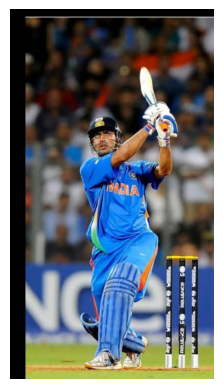

In [34]:
translated_rgb = cv2.cvtColor(translated, cv2.COLOR_BGR2RGB)

plt.imshow(translated_rgb)
plt.axis("off")
plt.show()

# Affine Transformation

In [35]:
height, width = image.shape[:2]

src_points = np.float32([
    [50, 50],
    [200, 50],
    [50, 200]
])

dst_points = np.float32([
    [100, 100],
    [250, 80],
    [80, 250]
])

In [36]:
M_affine = cv2.getAffineTransform(
    src_points,
    dst_points
)

In [37]:
affine = cv2.warpAffine(
    image,
    M_affine,
    (width, height)
)

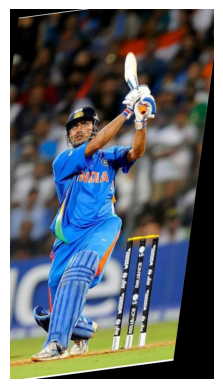

In [38]:
affine_rgb = cv2.cvtColor(affine, cv2.COLOR_BGR2RGB)

plt.imshow(affine_rgb)
plt.axis("off")
plt.show()

# Perspective Transformation

In [39]:
height, width = image.shape[:2]

src_points = np.float32([
    [100, 100],
    [500, 100],
    [500, 400],
    [100, 400]
])

dst_points = np.float32([
    [0, 0],
    [600, 0],
    [600, 400],
    [0, 400]
])

In [40]:
M_perspective = cv2.getPerspectiveTransform(
    src_points,
    dst_points
)

In [45]:
perspective = cv2.warpPerspective(
    image,
    M_perspective,
    (1300, 2400)
)

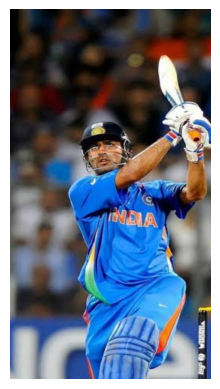

In [46]:
perspective_rgb = cv2.cvtColor(
    perspective,
    cv2.COLOR_BGR2RGB
)

plt.imshow(perspective_rgb)
plt.axis("off")
plt.show()

In [47]:
cv2.imwrite("images/resized.jpg", resized)
cv2.imwrite("images/cropped.jpg", cropped)
cv2.imwrite("images/rotated.jpg", rotated)
cv2.imwrite("images/flipped.jpg", flipped_horizontal)
cv2.imwrite("images/translated.jpg", translated)
cv2.imwrite("images/affine.jpg", affine)
cv2.imwrite("images/perspective.jpg", perspective)

True